# Project 1: Transactions – Pass 01



## Problem Definition



#### 1. State the business problem.

Translate the business problem into a Data Science problem by stating what kind of problem it is ( supervised vs unsupervised ) and whether it is a classification, regression, or clustering problem.  Mention which model will be used, if known.



> We want to predict whether or not a future customer will complete a transaction (e.g., a product purchase, loan or bill payment, or subscription retention) based on prior transaction data. Such predictions can help determine higher-risk customers and present incentives to drive future transaction completions and increase sales.

> This is a supervised, categorical binary classification problem, where the target data is whether a customer transaction was successful (true or false). To achieve this, it uses a Gaussian Naive Bayes model to make predictions about transaction success.



## Data Collection



#### 2. Load Pandas, Numpy, and Matplotlib modules

In [163]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn import datasets, metrics
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split

#### 3. Load data Train.csv from AWS S3.

In [164]:
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.1-Transactions/Data/Transaction.train.csv'

- Set number of columns and rows for this pass:

In [165]:
num_cols = 5
num_rows = 1_000

num_cols, num_rows

(5, 1000)

- Read in the data from .csv using pandas:

In [166]:
df = pd.read_csv(
    url,
    usecols=range(num_cols),
    nrows=num_rows,
)

- Check the dataframe:

In [167]:
df

,Unnamed: 0,ID_code,target,var_0,var_1
0,0,train_0,0,8.9255,-6.7863
1,1,train_1,0,11.5006,-4.1473
2,2,train_2,0,8.6093,-2.7457
3,3,train_3,0,11.0604,-2.1518
4,4,train_4,0,9.8369,-1.4834
...,...,...,...,...,...
995,995,train_995,0,10.5429,-3.1313
996,996,train_996,0,12.9541,-3.5607
997,997,train_997,0,4.2341,-8.5367
998,998,train_998,0,18.5600,2.3607


## Data Cleaning



#### 4. Examine the data using tools we have used in class. You should be identifying the various columns such as ...

    - target column
    - feature columns
    - identifier columns
    - null columns
    - null rows

    Tools you should be using include, but are not limited to:

    - head
    - tail
    - shape
    - size
    - info
    - describe
    - nunique
    - unique
    - isnull/isna



In [168]:
# define target_col
target_col = 'target'
target_col

'target'

- head

In [169]:
df.head()

,Unnamed: 0,ID_code,target,var_0,var_1
0,0,train_0,0,8.9255,-6.7863
1,1,train_1,0,11.5006,-4.1473
2,2,train_2,0,8.6093,-2.7457
3,3,train_3,0,11.0604,-2.1518
4,4,train_4,0,9.8369,-1.4834


- tail

In [170]:
df.tail()

,Unnamed: 0,ID_code,target,var_0,var_1
995,995,train_995,0,10.5429,-3.1313
996,996,train_996,0,12.9541,-3.5607
997,997,train_997,0,4.2341,-8.5367
998,998,train_998,0,18.5600,2.3607
999,999,train_999,0,10.5495,2.3825


- shape

In [171]:
df.shape

(1000, 5)

- size

In [172]:
df.size

5000

- info

In [173]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  1000 non-null   int64  
 1   ID_code     1000 non-null   object 
 2   target      1000 non-null   int64  
 3   var_0       1000 non-null   float64
 4   var_1       1000 non-null   float64
dtypes: float64(2), int64(2), object(1)
memory usage: 39.2+ KB


- describe

In [174]:
df.describe()

,Unnamed: 0,target,var_0,var_1
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,499.500000,0.097000,10.647679,-1.648351
std,288.819436,0.296106,3.046156,4.133810
min,0.000000,0.000000,2.825300,-13.202600
25%,249.750000,0.000000,8.418225,-4.858000
50%,499.500000,0.000000,10.460250,-1.760000
75%,749.250000,0.000000,12.656275,1.394700
max,999.000000,1.000000,19.122300,8.416000


- nunique

In [175]:
df.nunique()

,0
Unnamed: 0,1000
ID_code,1000
target,2
var_0,994
var_1,995


- unique

In [176]:
df[target_col].unique()

array([0, 1])

- isnull

In [177]:
df.isnull().sum().sort_values( ascending = False )

,0
Unnamed: 0,0
ID_code,0
target,0
var_0,0
var_1,0


In [178]:
(df.isnull().sum() / df.shape[0]).sort_values( ascending = False ) * 100

,0
Unnamed: 0,0.0
ID_code,0.0
target,0.0
var_0,0.0
var_1,0.0


- dtypes

In [179]:
df.dtypes

,0
Unnamed: 0,int64
ID_code,object
target,int64
var_0,float64
var_1,float64


#### 5. NOTE: the ‘target’ column indicates a successful transaction (‘1’) or a no-transaction (‘0’). Verify these are the only values in that column, and that there are no nulls.

In [180]:
df[target_col].value_counts( dropna = False )

,count
target,
0,903
1,97


In [181]:
df[[target_col]].shape[0]

1000

In [182]:
df[[target_col]].isnull().sum()

,0
target,0


- Summary:

  - target column: 'target'
  - feature columns: 'var_0', 'var_1'
  - identifier columns (likely): 'Unnamed', 'ID_code'
  - null columns: n/a
  - null rows: n/a

  No null values at all this pass.

#### 6. If there are data cleaning issues, develop recommendations for how to deal with them.  Specifically, handle these common issues:

    - identifer columns
    - target column with null counts
    - feature columns with high null counts
    - feature columns with low null counts
    - feature columns with medium null counts


In [183]:
df.head()

,Unnamed: 0,ID_code,target,var_0,var_1
0,0,train_0,0,8.9255,-6.7863
1,1,train_1,0,11.5006,-4.1473
2,2,train_2,0,8.6093,-2.7457
3,3,train_3,0,11.0604,-2.1518
4,4,train_4,0,9.8369,-1.4834


In [184]:
# 'Unnamed' and 'ID_code are very likely identifier columns, and should be dropped

# target, var_0, and var_1 are meaningful data columns and will be kept

In [185]:
# make backup
df_bak = df.copy()
df_bak

,Unnamed: 0,ID_code,target,var_0,var_1
0,0,train_0,0,8.9255,-6.7863
1,1,train_1,0,11.5006,-4.1473
2,2,train_2,0,8.6093,-2.7457
3,3,train_3,0,11.0604,-2.1518
4,4,train_4,0,9.8369,-1.4834
...,...,...,...,...,...
995,995,train_995,0,10.5429,-3.1313
996,996,train_996,0,12.9541,-3.5607
997,997,train_997,0,4.2341,-8.5367
998,998,train_998,0,18.5600,2.3607


In [186]:
# restore from backup
df = df_bak.copy()
df

,Unnamed: 0,ID_code,target,var_0,var_1
0,0,train_0,0,8.9255,-6.7863
1,1,train_1,0,11.5006,-4.1473
2,2,train_2,0,8.6093,-2.7457
3,3,train_3,0,11.0604,-2.1518
4,4,train_4,0,9.8369,-1.4834
...,...,...,...,...,...
995,995,train_995,0,10.5429,-3.1313
996,996,train_996,0,12.9541,-3.5607
997,997,train_997,0,4.2341,-8.5367
998,998,train_998,0,18.5600,2.3607


- This pass, keep only the target and two features:

In [187]:
target_cols  = [target_col]         # defined as 'target' above
feature_cols = ['var_0', 'var_1']
df = df[target_cols + feature_cols]

In [188]:
# check our dataframe (display transformed df)
df

,target,var_0,var_1
0,0,8.9255,-6.7863
1,0,11.5006,-4.1473
2,0,8.6093,-2.7457
3,0,11.0604,-2.1518
4,0,9.8369,-1.4834
...,...,...,...
995,0,10.5429,-3.1313
996,0,12.9541,-3.5607
997,0,4.2341,-8.5367
998,0,18.5600,2.3607


- backup 2

In [189]:
df_bak2 = df.copy()
df_bak2

,target,var_0,var_1
0,0,8.9255,-6.7863
1,0,11.5006,-4.1473
2,0,8.6093,-2.7457
3,0,11.0604,-2.1518
4,0,9.8369,-1.4834
...,...,...,...
995,0,10.5429,-3.1313
996,0,12.9541,-3.5607
997,0,4.2341,-8.5367
998,0,18.5600,2.3607


In [190]:
df = df_bak2.copy()
df

,target,var_0,var_1
0,0,8.9255,-6.7863
1,0,11.5006,-4.1473
2,0,8.6093,-2.7457
3,0,11.0604,-2.1518
4,0,9.8369,-1.4834
...,...,...,...
995,0,10.5429,-3.1313
996,0,12.9541,-3.5607
997,0,4.2341,-8.5367
998,0,18.5600,2.3607


In [191]:
# No rows have nulls, so we can skip imputing with fillna() and/or dropping rows

## Exploratory Data Analysis

Produce some visual analysis of the data.  Recall that Gaussian Naive Bayes assumes the features are normally distributed and independent. Note: you might have to do multiple plots in groups.



#### 7. Check the distributions of all variables by plotting.

array([[<Axes: title={'center': 'target'}>,
        <Axes: title={'center': 'var_0'}>],
       [<Axes: title={'center': 'var_1'}>, <Axes: >]], dtype=object)

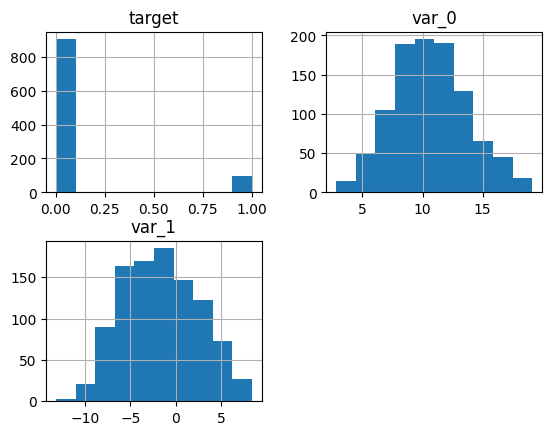

In [192]:
# Display a histogram
df.hist()

<Axes: >

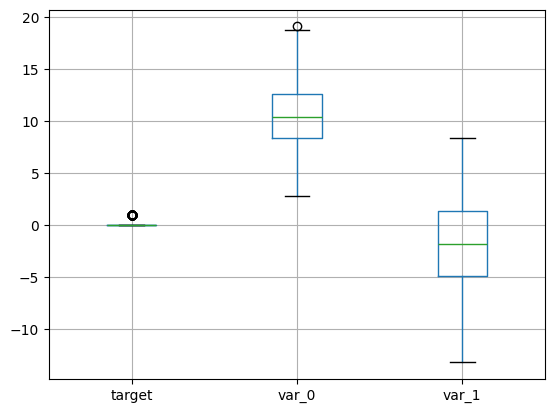

In [193]:
df.boxplot()

#### 8. Check the correlation values between all **feature columns** to ensure there are no substantial correlations between features. This is important to support the decision to classify the ‘target’ using Naïve Bayes.



In [194]:
column_correlations = df.corr()
column_correlations

,target,var_0,var_1
target,1.000000,-0.017817,0.101429
var_0,-0.017817,1.000000,0.016709
var_1,0.101429,0.016709,1.000000


<Axes: >

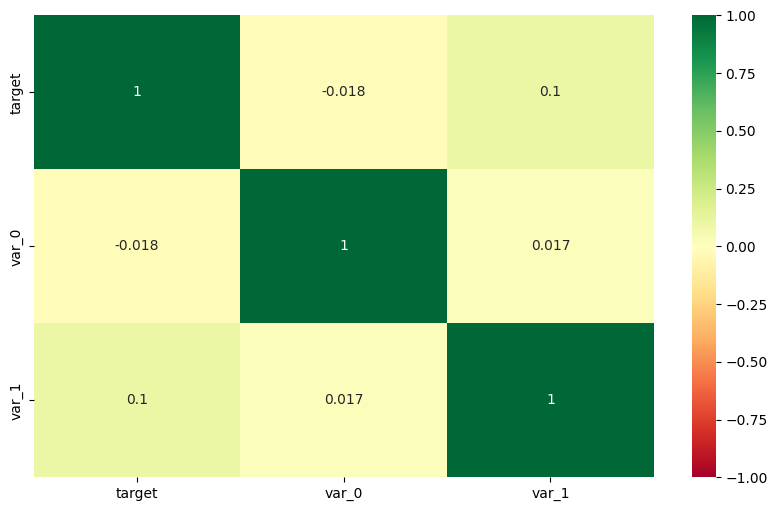

In [195]:
# Display correlation matrix
plt.figure(figsize = (10, 6))
sns.heatmap(
    column_correlations,
    annot = True,
    vmin = -1,
    vmax = 1,
    cmap = 'RdYlGn'
)

#### 9. Create two data frames: one with all successful transactions, one with all unsuccessful transactions. **Make sure they are copies and not slices**.




In [196]:
df_successful   = df[ df[target_col] == 1 ].copy()
df_successful

,target,var_0,var_1
13,1,16.3699,1.5934
29,1,5.3301,-2.6064
63,1,7.7072,0.0183
65,1,10.5358,-2.5439
71,1,6.7547,2.5973
...,...,...,...
939,1,7.6621,0.4167
948,1,9.2188,-2.8367
953,1,10.9433,1.2270
954,1,10.1926,-5.9643


In [197]:
df_unsuccessful = df[ df[target_col] == 0 ].copy()
df_unsuccessful

,target,var_0,var_1
0,0,8.9255,-6.7863
1,0,11.5006,-4.1473
2,0,8.6093,-2.7457
3,0,11.0604,-2.1518
4,0,9.8369,-1.4834
...,...,...,...
995,0,10.5429,-3.1313
996,0,12.9541,-3.5607
997,0,4.2341,-8.5367
998,0,18.5600,2.3607


## Data Processing



### Single Cross-validation ( CV )



#### 10. Create two data sets: one with all the feature columns (everything except for Unnamed: 0, ID_code and target) and one with just the target. Make sure they are copies and not slices.  And make sure they are the correct dimensions.



In [198]:
target   = df[ target_col ].copy()
features = df.drop( columns = [target_col] ).copy()

In [199]:
target

,target
0,0
1,0
2,0
3,0
4,0
...,...
995,0
996,0
997,0
998,0


In [200]:
target.value_counts()

,count
target,
0,903
1,97


In [201]:
type(target), target.shape, target.ndim

(pandas.core.series.Series, (1000,), 1)

In [202]:
features

,var_0,var_1
0,8.9255,-6.7863
1,11.5006,-4.1473
2,8.6093,-2.7457
3,11.0604,-2.1518
4,9.8369,-1.4834
...,...,...
995,10.5429,-3.1313
996,12.9541,-3.5607
997,4.2341,-8.5367
998,18.5600,2.3607


In [203]:
type(features), features.shape, features.ndim

(pandas.core.frame.DataFrame, (1000, 2), 2)

#### 11. Define an empty Gaussian Naïve Bayes model using Sklearn.



In [204]:
# Create an empty GNB model
modelGNB = GaussianNB()

#### 12. Divide the two data sets you created in step #10 into training and testing subsets, i.e. train-test split.



In [205]:
# Train Test Split
X_train, X_test, y_train, y_test = train_test_split( features, target, test_size = 0.25 )

#### 13. Train ( fit ) the model using the training subset of the dataset.



In [206]:
# Train ( fit ) the model
modelGNB.fit(X_train, y_train)

GaussianNB()

#### 14. Test the model ( predict ) using the testing subset of the dataset.



In [207]:
# Make predictions using the model
y_pred = modelGNB.predict(X_test)

#### 15. Calculate and report the accuracy.



In [208]:
# Calculate the accuracy and save to array
accuracy = metrics.accuracy_score(y_test, y_pred)
accuracy

0.908

#### 16. Present a confusion matrix and heatmap



Text(113.9222222222222, 0.5, 'Predicted')

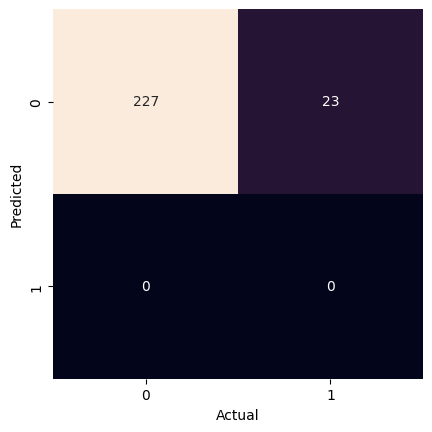

In [209]:
# Display confusion matrix
matrix = metrics.confusion_matrix(y_test, y_pred)
sns.heatmap(
    matrix.T,
    square = True,
    annot = True,
    fmt = 'd',
    cbar = False
)
plt.xlabel('Actual')
plt.ylabel('Predicted')

#### 17. Present the results of a Classification Report (sklearn.metrics.classification_report).

In [211]:
# 1. Generate the report (as a dictionary, for formatting)
report = metrics.classification_report(y_test, y_pred, output_dict = True, zero_division = 0)

# 2. Convert to DataFrame and transpose
df_report = pd.DataFrame(report).T
df_report

,precision,recall,f1-score,support
0,0.908000,1.000,0.951782,227.000
1,0.000000,0.000,0.000000,23.000
accuracy,0.908000,0.908,0.908000,0.908
macro avg,0.454000,0.500,0.475891,250.000
weighted avg,0.824464,0.908,0.864218,250.000
